In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import seaborn as sns
import html
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from collections import Counter
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import linregress

from datasets import load_dataset
from pathlib import Path


In [88]:
dataset = "TimKoornstra/financial-tweets-sentiment"

print("---Loading Dataset---")
ds = load_dataset(dataset, split="train")
df = ds.to_pandas()

---Loading Dataset---


In [89]:
# Tải file raw ra data
ROOT = Path.cwd()

raw_output_dir = ROOT / ".." / "data" / "raw" / "text_b"
raw_output_dir.mkdir(parents=True, exist_ok=True)

raw_output_file = raw_output_dir / "financial_tweets_sentiment_raw.csv"
df.to_csv(raw_output_file)

In [90]:
print(df.info())
print("\nPhân bố nhãn:\n", df["sentiment"].value_counts())
print(df.head(5))

<class 'pandas.DataFrame'>
RangeIndex: 38091 entries, 0 to 38090
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   tweet      38091 non-null  str  
 1   sentiment  38091 non-null  int64
 2   url        38091 non-null  str  
dtypes: int64(1), str(2)
memory usage: 6.8 MB
None

Phân bố nhãn:
 sentiment
1    17368
0    12181
2     8542
Name: count, dtype: int64
                                               tweet  sentiment  \
0  $BYND - JPMorgan reels in expectations on Beyo...          2   
1  $CCL $RCL - Nomura points to bookings weakness...          2   
2  $CX - Cemex cut at Credit Suisse, J.P. Morgan ...          2   
3  $ESS: BTIG Research cuts to Neutral https://t....          2   
4  $FNKO - Funko slides after Piper Jaffray PT cu...          2   

                                                 url  
0  https://huggingface.co/datasets/zeroshot/twitt...  
1  https://huggingface.co/datasets/zeroshot/twitt...  
2  https:

In [91]:
# LABEL cho giá trị
# 0: Neutral (Trung tính)
# 1: Bullish (Tích cực / Kỳ vọng tăng)
# 2: Bearish (Tiêu cực / Kỳ vọng giảm)
label_map = {
    0: "Neutral",
    1: "Bullish",
    2: "Bearish"
}

df["label"] = df["sentiment"].map(label_map)

## 1. Text EDA

In [92]:
from IPython.display import display

def plot_text_eda(text: pd.Series, label: pd.Series):
    if len(text) != len(label):
        print(f"Invalid Length: {len(text)} != {len(label)}")
        return

    eda_df = pd.DataFrame({
        "label": label,
        "text_length": text.str.len(),                 # Độ dài văn bản (gồm khoảng trắng)
        "char_count": text.str.count(r"\S"),           # Số ký tự (không tính khoảng trắng)
        "word_count": text.str.split().str.len(),      # Số từ
    })

    label_order = ["Bullish", "Neutral", "Bearish"]
    palette = {
        "Bullish": "#2ecc71",  
        "Neutral": "#3498db",  
        "Bearish": "#e74c3c", 
    }

    metrics = [
        ("text_length", "Text Length"),
        ("char_count", "Character Count"),
        ("word_count", "Word Count"),
    ]

    # TÍNH: Bảng thống kê theo từng nhãn lớp
    for col, title in metrics:
        stats = (
            eda_df.groupby("label")[col]
            .agg(
                count="count",
                mean="mean",
                std="std",
                min="min",
                q25=lambda s: s.quantile(0.25),
                median="median",
                q75=lambda s: s.quantile(0.75),
                max="max",
            )
            .reindex(label_order)
            .round(2)
        )
        print(f"\n=== Thống kê: {title} ===")
        display(stats)

    sns.set_theme(style="whitegrid", font_scale=1.05)
    fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(15, 12))

    for row_idx, (col, title) in enumerate(metrics):
        ax_kde, ax_box = axes[row_idx, 0], axes[row_idx, 1]

        upper_limit = eda_df[col].quantile(0.995)
        sub_df = eda_df[eda_df[col] <= upper_limit]

        # Cột trái: Đường mật độ KDE
        sns.kdeplot(
            data=sub_df,
            x=col,
            hue="label",
            hue_order=label_order,
            palette=palette,
            common_norm=False,   # Chuẩn hóa riêng từng lớp vì số mẫu 3 lớp lệch nhau
            fill=True,
            alpha=0.15,
            linewidth=2,
            cut=0,               
            ax=ax_kde,
        )
        ax_kde.set_title(f"Density Distribution: {title}", fontweight="bold")
        ax_kde.set_xlabel(title)
        ax_kde.set_ylabel("Density")

        # Cột phải: Boxplot tách riêng 3 nhãn thành 3 dòng
        sns.boxplot(
            data=sub_df,
            x=col,
            y="label",
            order=label_order,
            hue="label",
            hue_order=label_order,
            palette=palette,
            legend=False,
            width=0.5,
            fliersize=2.5,
            ax=ax_box,
        )
        ax_box.set_title(f"Compare among labels: {title}", fontweight="bold")
        ax_box.set_xlabel(title)
        ax_box.set_ylabel("")

    sns.despine()
    plt.tight_layout()
    plt.show()
    
    return eda_df.drop(columns=['label'])


=== Thống kê: Text Length ===


,count,mean,std,min,q25,median,q75,max
label,,,,,,,,
Bullish,17368,93.88,71.93,3,52.0,83.0,131.0,3507
Neutral,12181,94.43,49.82,1,58.0,85.0,131.0,359
Bearish,8542,99.53,97.38,5,54.0,84.0,132.0,4229



=== Thống kê: Character Count ===


,count,mean,std,min,q25,median,q75,max
label,,,,,,,,
Bullish,17368,78.54,59.51,2,44.0,70.0,109.0,2864
Neutral,12181,81.04,42.27,0,50.0,73.0,114.0,316
Bearish,8542,83.38,80.63,4,45.0,71.0,110.0,3525



=== Thống kê: Word Count ===


,count,mean,std,min,q25,median,q75,max
label,,,,,,,,
Bullish,17368,15.42,12.45,1,8.0,13.0,20.0,636
Neutral,12181,13.83,7.83,0,9.0,12.0,18.0,63
Bearish,8542,16.49,16.75,1,9.0,13.0,21.0,701


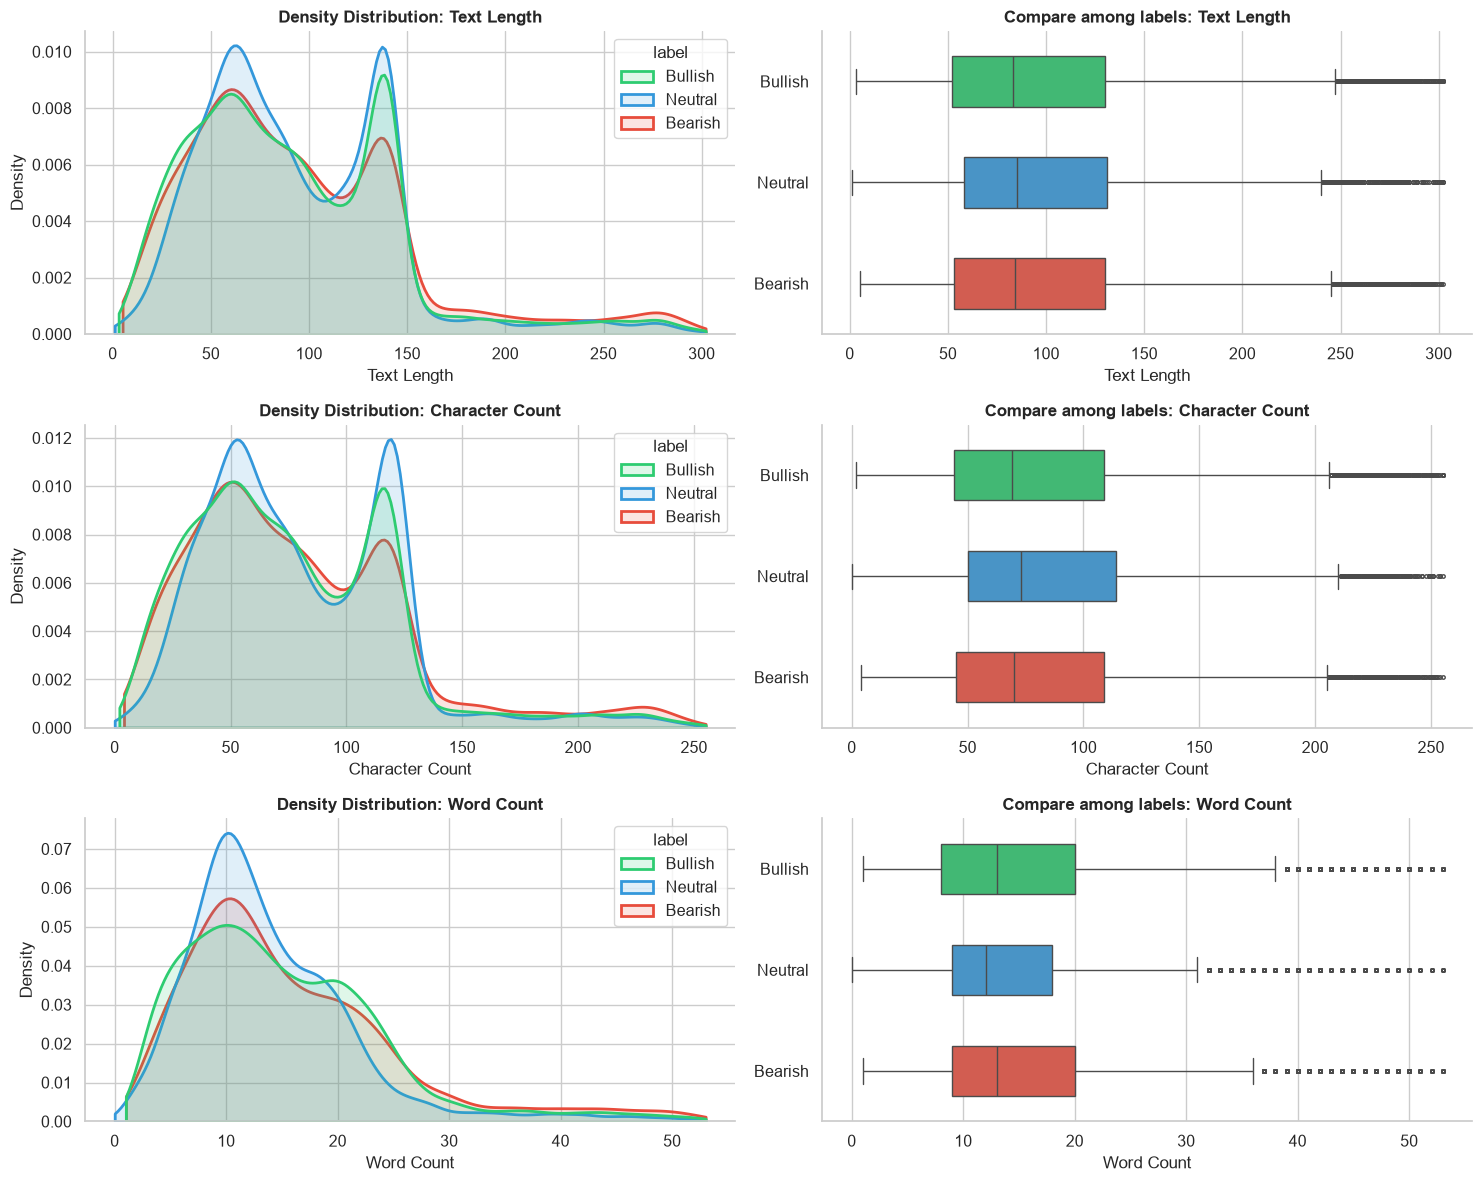

In [93]:
eda_df = plot_text_eda(df["tweet"], df['label'])
df = pd.concat([df, eda_df], axis=1)

### Đánh giá sơ tổng quan
- Có sự chênh lệch lớn giữa nhãn Neutral giữa Bullish và Bearish, max của Netrual thường rất nhỏ, trong khi Bullish và Bearish lại lớn hơn rất nhiều.

- Đáng chú ý, Neutral có các đoạn text outlier có min Character và min Word = 0, và Bearish, Bullish cũng có những giá trị min rất thấp, có thể không mang thông tin hữu ích về ngữ nghĩa.

- Mật độ tập trung cao ở **vùng 50-140** sau đó giảm dần dần về 300

- Nhìn Boxplot, ta thấy sự phân phối lệch phải, khi đường **Median** nằm lệch về phía bên trái hình hộp và mean > median ở mọi label

- Cả 3 thống kê có các khoảng Q25, Q75 và Median gần như trùng khít nhau.

---

## Kiểm định Mann-Whitney U test
- Kiểm định thống kê **phi tham số (non-parametric)** dùng để **so sánh 2 nhóm độc lập**, nhằm kiểm tra xem 1 nhóm có xu hướng mang giá trị lớn/nhỏ hơn nhóm kia 1 cách 1 hệ thống hay không.

- Giải quyết triệt để ngoại lai, vì loại bỏ giá trị độ dài tuyệt đối và chỉ dựa vào Rank

### 1. Cách hoạt động
- Ghép mọi câu lớp A và B lại rồi xếp từ ngắn đến dài theo **Rank**

- Đếm số lần câu thuộc lớp A dài hơn câu lớp B

### 2. Kiểm định giả thuyết
- *$H_0$*: Hai lớp có phân phối độ dài như nhau (xác suất chọn ngẫu nhiên 1 câu lớp này dài hơn câu lớp kia = 50%)

- *$H_1$*: Tồn tại sự chênh lệch có hệ thống về độ dài giữa hai lớp

**Kết quả P-value (với mức ý nghĩa $\alpha = 0.05$):**
*   **P-value < 0.05 (Bác bỏ $H_0$):** Hai lớp có sự khác biệt có ý nghĩa thống kê
*   **P-value $\ge$ 0.05 (Chưa đủ cơ sở bác bỏ $H_0$):** 2 lớp không có sự khác biệt đáng kể

### 3. Hiệu chỉnh Bonferroni
- Vì Man-Whiteney U test chỉ so sánh 2 nhóm, mà tập dữ liệu có 3 nhãn nên cần phải thực hiện 3 phép kiểm định cho mỗi metrics

- Nếu ta giữ nguyên ngưỡng $\alpha$ = 0.05, thì xác suất mắc ít nhất **1 Sai lầm loại I** sẽ phìm lên rất to thành $1- (1-0.05)^3 \approx 14.3%$

**Công thức:**
$$
p_{bonferroni} = min(p_{raw} × m, 1)
$$

### 4. Độ lớn hiệu ứng - Effect Size ($r_{rb}$)
- Vì **p-value** chi cho biết sự khác biệt có phải là ngẫu nhiên hay không, chứ không phải **đo độ lớn** của sự khác biệt.

- Với cỡ mẫu lớn (N = ~ 38.000), khiến cho độ nhạy của p-value rất lớn - một độ lệch nhỏ không có ý nghĩa sẽ có thể đẩy p-value tiệm cận 0.
- Ta sử dụng giá trị r_rb:
**Công thức:**
$$
r_{rb} =  \frac{2 \cdot U_1} {n_1 \cdot n_2} - 1 \in [−1,1]
$$

- **Dấu của $r_{rb}$:** Cho biết chiều chênh lệch

- **Trị tuyệt đối |$r_{rb}$|**:
    - **|$r_{rb}$| < 0.1:** Lệch không đáng kể
    - **0.1 <= |$r_{rb}$| < 0.3:** Lệch nhỏ
    - **0.3 <= |$r_{rb}$| < 0.5:** Lệch trung bình.
    - **|$r_{rb}$| >= 0.5:** Lệch lớn

In [94]:
from scipy.stats import mannwhitneyu
from itertools import combinations

labels = df['label'].unique()
# Tổ hợp chập 2 của các labels
label_combs = list(combinations(labels, 2))

alpha = 0.05

res = []

for target in ['text_length', 'char_count', 'word_count']:
    
    for(l1, l2) in label_combs:
        l1_length = df[df['label'] == l1][target]
        l2_length = df[df['label'] == l2][target]
        
        stat, p = mannwhitneyu(
            l1_length, l2_length,
            alternative='two-sided',
            method='auto'
            )
        
        p_bonferroni = min(p * len(label_combs), 1)
        
        r_rb = (2 * stat / (len(l1_length) * len(l2_length))) - 1
        
        res.append({
            'metric': target,
            'pair': f'{l1} vs {l2}',
            'u_stat': stat,
            'p_raw': p,
            'p_bonferroni': p_bonferroni,
            'reject_H0': p_bonferroni < alpha,
            'r_rb': round(r_rb, 4),
            'abs_r_rb': round(abs(r_rb), 4),
        })
    
res_df = pd.DataFrame(res)
display(res_df)

,metric,pair,u_stat,p_raw,p_bonferroni,reject_H0,r_rb,abs_r_rb
0,text_length,Bearish vs Bullish,75953567.5,1.710701e-03,5.132102e-03,True,0.0239,0.0239
1,text_length,Bearish vs Neutral,51104782.0,2.989704e-02,8.969111e-02,False,-0.0177,0.0177
2,text_length,Bullish vs Neutral,101265634.0,3.953152e-10,1.185946e-09,True,-0.0427,0.0427
3,char_count,Bearish vs Bullish,76094313.5,7.127486e-04,2.138246e-03,True,0.0258,0.0258
4,char_count,Bearish vs Neutral,49656543.5,2.301996e-08,6.905989e-08,True,-0.0455,0.0455
5,char_count,Bullish vs Neutral,97857784.5,4.976692e-28,1.493008e-27,True,-0.0749,0.0749
6,word_count,Bearish vs Bullish,76305227.0,1.698714e-04,5.096142e-04,True,0.0287,0.0287
7,word_count,Bearish vs Neutral,57141204.5,1.305528e-33,3.916585e-33,True,0.0983,0.0983
8,word_count,Bullish vs Neutral,113366727.5,6.889438e-26,2.066831e-25,True,0.0717,0.0717


### Đánh giá khảo sát Mann-Whitney U test
- Có 8/9 tổ hợp metric cho ra **bác bỏ H0**, nghĩa là 2 lớp có khác biệt có ý nghĩa thống kê.

- Nhưng 8/9 các kết quả metrics đều do **cỡ mẫu rất lớn** làm **tăng độ nhạy của P-value** (khi N càng lớn thì Z càng lớn làm cho P-value càng giảm -> Bác bỏ H0)

- Ta phải đánh giá thêm **Effect Size (giá trị tuyệt đối r_rb):**

- Ta thấy **|r_rb| < 0.1** trên mọi metrics. Do đó, các lớp **KHÔNG** có sự khác biệt đáng kể về độ dài trên thực tế 

- Giá trị duy nhất cho ra False cho bác bỏ H0, khi nhìn **p_raw(0.029) < 0.05** nhưng **p_bonferroni(0.0897) > 0.05**, cho thấy hiệu chỉnh Bonferroni đã chặn tín hiệu giả.

- Dấu của giá **trị r_rb** chỉ đảo chiều nhẹ.
---

## Word Cloud
**Bản chất:** biểu đồ trực quan hóa tần suất từ — từ xuất hiện càng nhiều thì kích thước chữ càng lớn

**Ý nghĩa:**

- Phát hiện nhanh "nhiễu" (Noise Discovery)

- Đánh giá sơ bộ khả năng phân tách lớp

- Phát hiện nguy cơ học vẹt

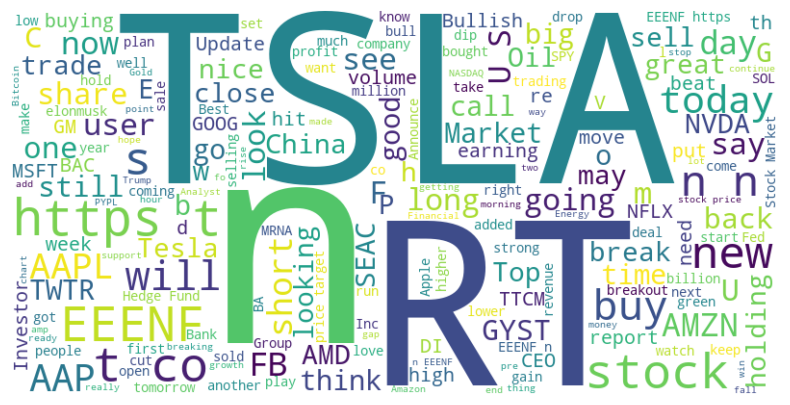

In [95]:
from wordcloud import WordCloud, STOPWORDS

wc = WordCloud(
    width=800,
    height=400,
    stopwords=STOPWORDS,
    background_color="White",
).generate(df["tweet"].to_string())
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")  # Ẩn trục tọa độ
plt.show()

# Expected: các word ko có ý nghĩa gì, vì chưa cleaning


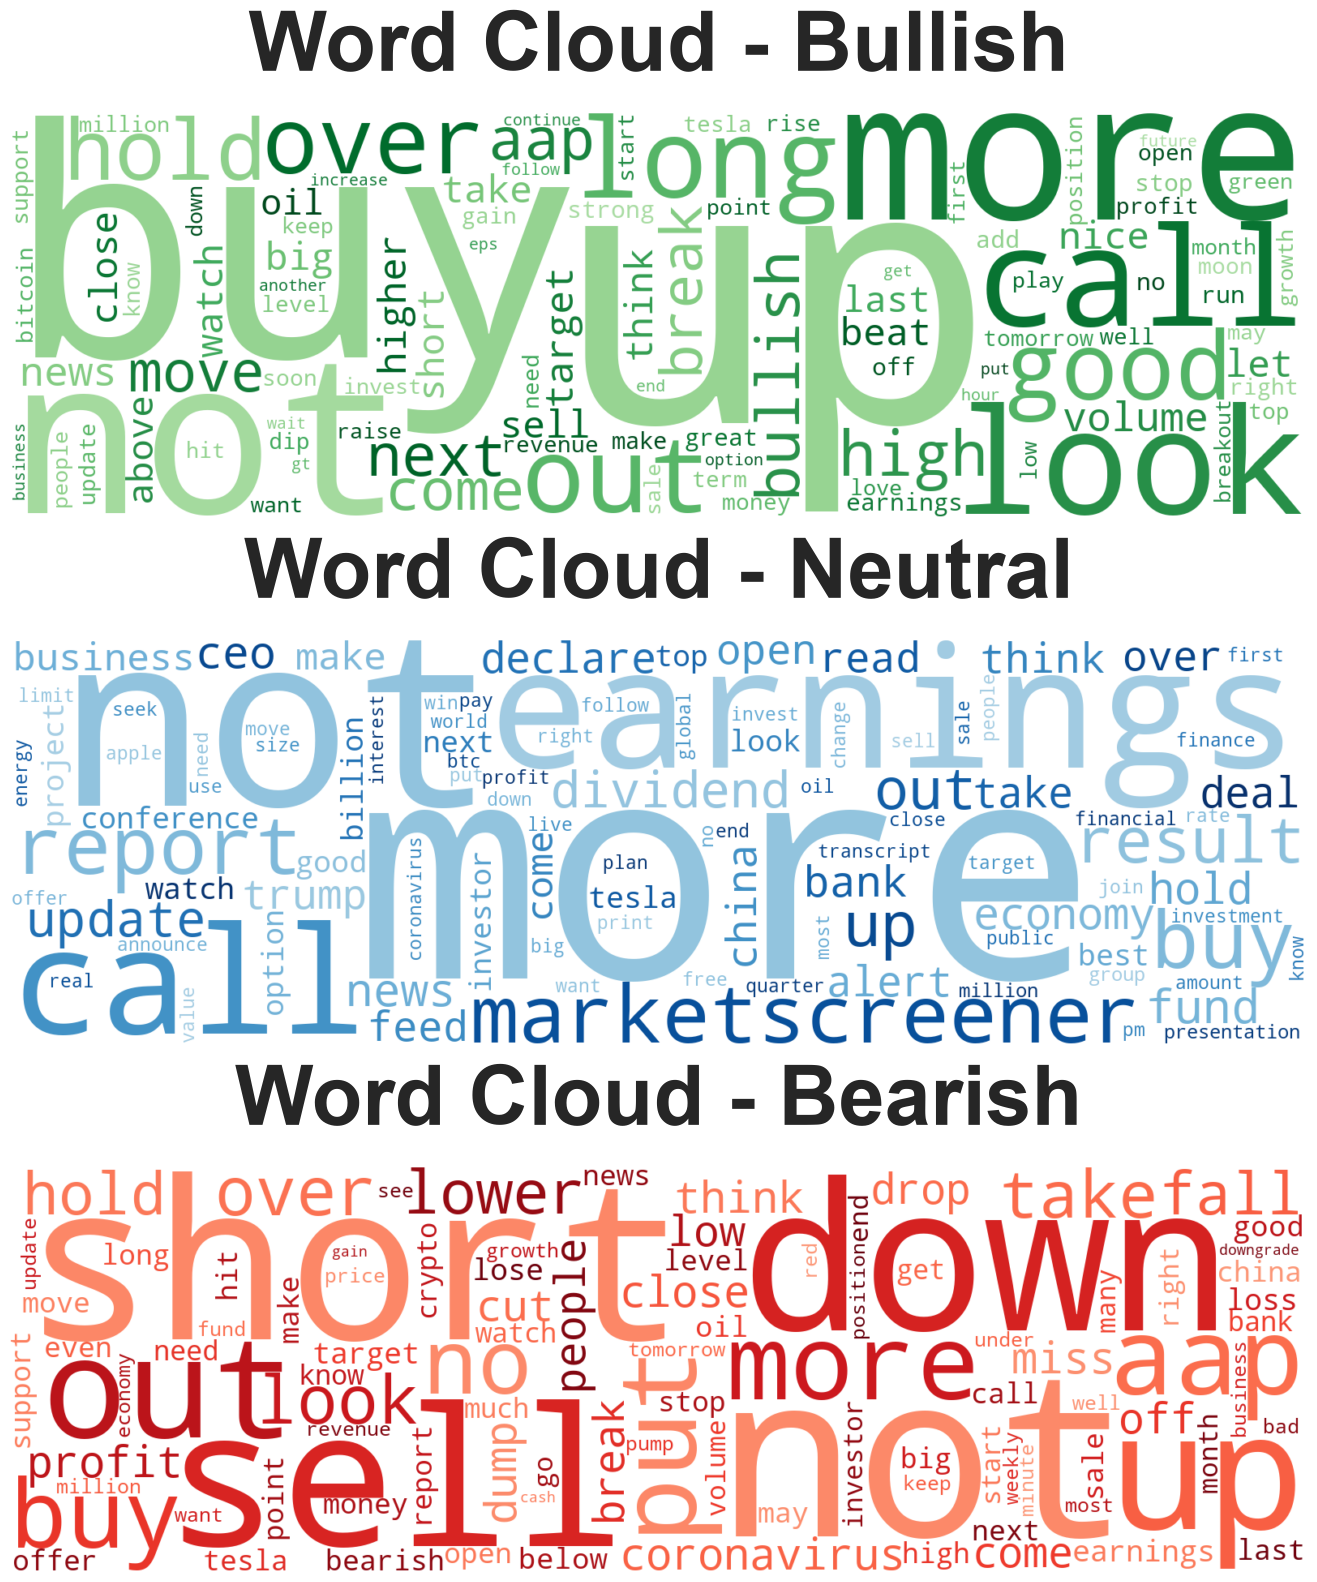

In [96]:
# Cleaning trước khi dùng word cloud
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

lemmatizer = WordNetLemmatizer()

BASE_STOPWORDS = set(STOPWORDS) | set(stopwords.words("english")) | {
    "will", "now", "rt", "via", "amp", "co", "us", "one", "new",
    "today", "day", "week", "year", "time", "still", "back",
    "see", "make", "go", "going", "get", "got", "say", "says", "said",
    "user",
}

KEEP_WORDS = {
    "not", "no", "nor", "never", "up", "down", "above", "below",
    "over", "under", "more", "most", "less", "against", "off", "out",
}

DOMAIN_STOPWORDS = {
    "stock", "stocks", "market", "markets", "share", "shares",
    "company", "companies", "price", "trade", "trading", "trader",
    "inc", "corp", "ltd", "pt", "etf", "nyse", "nasdaq",
}

EDA_STOPWORDS = (BASE_STOPWORDS | DOMAIN_STOPWORDS) - KEEP_WORDS


def truncate_cmap(name, minval=0.35, maxval=1.0, n=256):
    cmap = plt.get_cmap(name)
    return LinearSegmentedColormap.from_list(
        f"trunc_{name}", cmap(np.linspace(minval, maxval, n))
    )

def clean_and_tokenize_eda(text: pd.Series, remove_stopwords=True, remove_cashtags=False):
    tokens = []
    
    for text in text.dropna():
        text = text.lower()
        text = re.sub(r'https?://\S+|www\.\S+', " ", text) # URL
        text = re.sub(r'@\w+', " ", text) # @
        text = re.sub(r'&amp;', " ", text) #HTML
        
        # Bung các từ viết tắt phổ biến trước khi tách từ
        text = re.sub(r"\bwon't\b", "will not", text)
        text = re.sub(r"\bcan't\b", "cannot", text)
        text = re.sub(r"n't\b", " not", text)
        text = re.sub(r"'s\b", "", text)
        text = re.sub(r"'(re|ve|ll|d|m)\b", " ", text)

        # Bỏ dấu # nhưng giữ từ bên trong hashtag
        text = re.sub(r"#", "", text)

        # Gom ký tự kéo dài (vd: buuuuuy -> buuy)
        text = re.sub(r"(.)\1{2,}", r"\1\1", text)
        
        if remove_cashtags:
            text = re.sub(r'\$[a-z0-9._-]+', " ", text)
            words = re.findall(r'[a-z]{2,}', text)
            
        else:
            words = re.findall(r'\$[a-z]+|[a-z]{2,}', text)
        
        if remove_stopwords:
            words = [w for w in words if w not in EDA_STOPWORDS and len(w) >= 2]
        
        # Lemmatize (danh từ -> động từ) để gom stock/stocks, cut/cuts...
        words = [lemmatizer.lemmatize(lemmatizer.lemmatize(w, pos="n"), pos="v") for w in words]
        
            
        
        tokens.extend(words)
    
    return tokens

# Đếm frequency

label_order = ["Bullish", "Neutral", "Bearish"]
cmaps = {
    "Bullish": truncate_cmap("Greens"),
    "Neutral": truncate_cmap("Blues"),
    "Bearish": truncate_cmap("Reds"),
}

class_counters = {}

class_counters = {
    l: Counter(clean_and_tokenize_eda(df.loc[df["label"] == l, "tweet"], remove_cashtags=True))
    for l in label_order
}

fig, axes = plt.subplots(3, 1, figsize=(18, 16))

for ax, l in zip(axes, label_order):
    wc = WordCloud(
        width=1600,
        height=500,
        max_words=100,
        background_color="white",
        colormap=cmaps[l],
        random_state = 42
    ).generate_from_frequencies(class_counters[l])
    
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(f"Word Cloud - {l}", fontsize = 60, fontweight="bold", pad = 30)
    ax.axis("off")

plt.tight_layout()
plt.show()
    

## Nhận xét về Word Cloud

### 1. Đánh giá khả năng phân tách lớp (Class Separability)
- **Bullish:** Nổi bật các từ khóa mang sắc thái lạc quan, kỳ vọng tăng trưởng và hành động mua vào như `buy`, `up`, `above`, `good`, `high`, `big`, `love`, `revenue`,...

- **Neutral:** Ít từ ngữ cảm xúc mạnh hơn hẳn; thay vào đó là nhóm từ mang tính thông tin, báo cáo tài chính và tin tức vĩ mô/chính trị như `earnings`, `call`, `ceo`, `bank`, `report`, `conference`, `china`, `trump`, `global`, `world`,...

- **Bearish:** Thể hiện rõ xu hướng tiêu cực và bán tháo qua các từ như `short`, `down`, `sell`, `out`, `lower`, `miss`, `bearish`,...

- **Vùng giao thoa (Overlap) giữa 3 lớp:** Các từ như `not`, `buy`, `call`, `tesla` (và cả `sell` ở Bullish lẫn Bearish) xuất hiện dày ở nhiều lớp. Điều này cho thấy:
  - Từ phủ định `not` (được chủ động giữ lại) xuất hiện đều ở cả 3 lớp vì nó đóng vai trò **đảo ngược cực tính** của từ đi kèm (ví dụ *"not selling"* → Bullish vs *"not buying"* → Bearish).

  - Do đó, biểu diễn văn bản chỉ bằng từ đơn (**Unigram**) dễ gây nhầm lẫn; ở bước huấn luyện mô hình nên dùng **N-gram (bi-gram/tri-gram)** cho TF-IDF hoặc các mô hình nhận thức ngữ cảnh (Transformer/FinBERT).

### 2. Phát hiện nhiễu (Noise Discovery)
- Khi kiểm tra trực tiếp các tweet chứa từ lạ `aap` (xuất hiện nổi bật trong Bullish), phát hiện đây **không phải** mã cổ phiếu Advance Auto Parts mà là lỗi **mất ký tự (`L`, `R`) từ nguồn thu thập dữ liệu gốc** (ví dụ: `AAPL` → `AAP`, `LONG` → `ONG`, `FEAR/GREED` → `FEA/GEED`, `Larry` → `arry`), đồng thời các thẻ `@mention` đã bị thay bằng token `user` và cashtag mất dấu `$` nên bộ lọc cashtag không bắt được.

- Sự xuất hiện của `marketscreener` trong Neutral cũng cho thấy sự tồn tại của nguồn tin tự động/bot đăng bài tin tức chứng khoán.

In [97]:
# 1. Xem các nguồn dữ liệu gốc trong cột url
print(df["url"].value_counts())

# 2. Kiểm tra các tweet chứa 'AAP' (không có L) thuộc nguồn nào
mask_aap = df["tweet"].str.contains(r"\bAAP\b", na=False)
print("\nSố tweet chứa 'AAP':", mask_aap.sum())
print(df.loc[mask_aap, "url"].value_counts())

url
https://huggingface.co/datasets/zeroshot/twitter-financial-news-sentiment    11931
https://github.com/moritzwilksch/MasterThesis/tree/main                       8662
https://www.kaggle.com/datasets/mattgilgo/stock-related-tweet-sentiment       6482
https://www.kaggle.com/datasets/yash612/stockmarket-sentiment-dataset         5791
https://github.com/poojathakoor/twitter-stock-sentiment                       1778
https://ieee-dataport.org/open-access/stock-market-tweets-data                1284
https://huggingface.co/datasets/ChanceFocus/fiqa-sentiment-classification     1111
https://github.com/surge-ai/crypto-sentiment/tree/main                         552
https://github.com/surge-ai/stock-sentiment/tree/main                          500
Name: count, dtype: int64

Số tweet chứa 'AAP': 889
url
https://www.kaggle.com/datasets/yash612/stockmarket-sentiment-dataset    888
https://github.com/moritzwilksch/MasterThesis/tree/main                    1
Name: count, dtype: int64


In [98]:
# Top-50
top_n = 50
rows = {}

for l in label_order:
    top_words = class_counters[l].most_common(top_n)
    rows[f"{l}_word"] = [w for w, _ in top_words]
    rows[f"{l}_count"] = [c for _, c in top_words]

top50_df = pd.DataFrame(rows, index=range(1, top_n + 1))
top50_df.index.name = "Rank"

print("---------------------------------------Top 50 ---------------------------------------")
display(top50_df)

---------------------------------------Top 50 ---------------------------------------


,Bullish_word,Bullish_count,Neutral_word,Neutral_count,Bearish_word,Bearish_count
Rank,,,,,,
1,up,1711,more,536,not,891
2,buy,1626,not,492,short,823
3,not,1030,earnings,484,down,700
4,more,878,call,483,sell,617
5,look,812,marketscreener,465,up,431
6,call,806,buy,454,out,414
7,long,759,report,452,aap,411
8,out,685,result,435,put,404
9,good,649,up,403,more,388


---

## Type Token Ratio (TTR)

- Chỉ sô đo độ đa dạng, phong phú từ vựng

**Công thức TTR:** Tỉ lệ giữa số từ duy nhất và tổng số từ 
$$
TTR = \frac {V}{N} = \frac{\text{Số lượng Type}} {\text{Số lượng Token}}
$$

- **Token (N):** Tổng số từ xuất hiện trong văn bản
- **Type (V - Vocabulary Size):** Số lượng từ duy nhất

### STTR: là biến thể của TTR khi áp dụng TTR cho 1 chunk size và gộp lại tính mean

In [99]:
def compute_ttr_sttr(tokens, chunk_size=1000):
    n_tokens = len(tokens)
    n_types = len(set(tokens))
    
    ttr = n_types / n_tokens if n_tokens > 0 else 0.0
    
    n_chunks = n_tokens // chunk_size
    
    if n_chunks == 0:
        sttr = ttr
    else:
        chunk_ttrs = [
            len(set(tokens[i * chunk_size : (i + 1) * chunk_size])) / chunk_size
            for i in range(n_chunks)
        ]
        sttr = float(np.mean(chunk_ttrs))
    return n_tokens, n_types, ttr, sttr

In [100]:
ttr_rows = []

# 1. Tính cho từng lớp
for l in label_order:
    series = df.loc[df["label"] == l, "tweet"].sample(frac=1, random_state=42)
    tokens = clean_and_tokenize_eda(series, remove_stopwords=True, remove_cashtags=True)
    
    n_tokens, n_types, ttr, sttr = compute_ttr_sttr(tokens, chunk_size=1000)
    ttr_rows.append({
        "Class": l,
        "Tokens (N)": n_tokens,
        "Types (V)": n_types,
        "TTR (V/N)": round(ttr, 4),
        "STTR (1000-tok)": round(sttr, 4),
    })

# 2. Tính cho toàn bộ dataset (Overall)
all_series = df["tweet"].sample(frac=1, random_state=42)
all_tokens = clean_and_tokenize_eda(all_series, remove_stopwords=True, remove_cashtags=True)
n_tokens, n_types, ttr, sttr = compute_ttr_sttr(all_tokens, chunk_size=1000)

ttr_rows.append({
    "Class": "Overall",
    "Tokens (N)": n_tokens,
    "Types (V)": n_types,
    "TTR (V/N)": round(ttr, 4),
    "STTR (1000-tok)": round(sttr, 4),
})

ttr_df = pd.DataFrame(ttr_rows)
display(ttr_df)

,Class,Tokens (N),Types (V),TTR (V/N),STTR (1000-tok)
0,Bullish,123872,12006,0.0969,0.6650
1,Neutral,90159,13711,0.1521,0.7370
2,Bearish,72713,9315,0.1281,0.6818
3,Overall,286744,22212,0.0775,0.7110


## Đánh giá độ phong phú từ vựng
- Vì hiệu ứng bão hòa từ vựng theo **định luật Heap** - khi tổng số token ($N$) tăng rất lớn, các từ đã xuất hiện cứ lặp đi lặp lại trong khi số từ mới ($V$) tăng chậm dần, kéo tỷ số $V/N$ tụt xuống.

- Ta dễ dàng thấy cả 4 metrics đều cho ra TTR có độ phong phú không quá 2%, nhưng nhìn lại STTR lại cho ra độ phong phú > 66% mọi tập, với **Neutral** đạt cao nhất (~73.7%)

- Neutral có từ vựng phong phú nhất (STTR = 0.7370): Thậm chí số từ duy nhất của **Neutral (13,711 types)** còn nhiều hơn cả **Bullish (12,006 types)** dù Neutral ít hơn tới hơn **33.000 tokens**.

- Bullish (0.6650) và Bearish (0.6818) có độ lặp từ cao hơn.

### Lí giải
- Vì ta đã lọc bỏ stopwords lặp nhiều, và chỉ giữ lại từ có ý nghĩa nên phần nào đã kéo TTR và STTR.

- Hơn thế nữa vì đây là tweet về tài chính, các tweet nói về mã cổ phiếu khác nhau đã góp phần tạo nên độ đa dạng của từ vựng.

- Neutral là nhóm tin tức trung lập bao phủ nhiều chủ đề rộng (kinh tế vĩ mô, báo cáo tài chính, etc).

- Bullish và Bearish mang 1 sắc thái cảm xúc rõ ràng nên các từ vựng lặp lại, xoay quay 1 số từ hẹp chỉ cảm xúc đó.

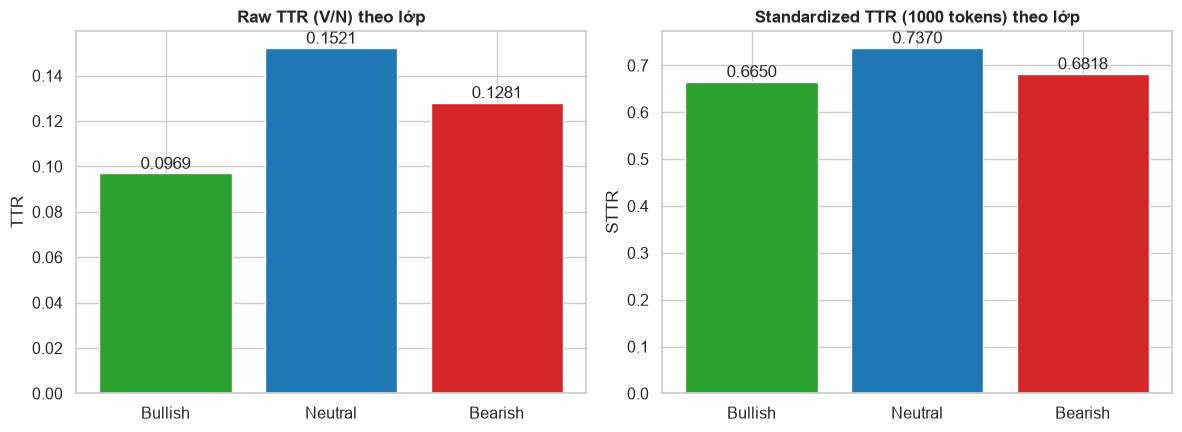

In [101]:
import matplotlib.pyplot as plt

plot_df = ttr_df[ttr_df["Class"] != "Overall"]
colors = ["#2ca02c", "#1f77b4", "#d62728"]  # Xanh lá, xanh dương, đỏ

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Biểu đồ 1: TTR thô
axes[0].bar(plot_df["Class"], plot_df["TTR (V/N)"], color=colors)
axes[0].set_title("Raw TTR (V/N) theo lớp", fontweight="bold")
axes[0].set_ylabel("TTR")
for i, v in enumerate(plot_df["TTR (V/N)"]):
    axes[0].text(i, v + 0.002, f"{v:.4f}", ha="center")

# Biểu đồ 2: STTR
axes[1].bar(plot_df["Class"], plot_df["STTR (1000-tok)"], color=colors)
axes[1].set_title("Standardized TTR (1000 tokens) theo lớp", fontweight="bold")
axes[1].set_ylabel("STTR")
for i, v in enumerate(plot_df["STTR (1000-tok)"]):
    axes[1].text(i, v + 0.01, f"{v:.4f}", ha="center")

plt.tight_layout()
plt.show()

---

## Phân tích phân phối Zipf

**Định luật Zipf (Zipf's Law):** Thứ tự tần suất xuất hiện giảm dần, tần suất của một từ sẽ tỷ lệ nghịch với thứ hạng (rank) của nó.

**Công thức:**
$$
f(r) \approx \frac{C}{r^{\alpha}}
$$

Với:

- **$r \in \{1, 2, 3, \dots, V\}$:** thứ hạng (Rank)
- $f(r)$ là tần suất xuất hiện của từ đứng hạng $r$.
- $C$ là hằng số.
- $\alpha$ là số mũ đặc trưng (với định luật Zipf lý tưởng trong ngôn ngữ tự nhiên, $\alpha \approx 1$).

**Công thức Zipf theo Log-Log:**
$$
\log_{10} f(r) = \log_{10} C - \alpha \cdot \log_{10} r
$$

=== Chưa lọc Stopwords (N = 464,088, V = 22,324) ===
Estimated alpha (log-binned): 1.0252 | R²: 0.9716
Hapax legomena (freq = 1)   : 10,832 / 22,324 (48.52%)

=== Đã lọc Stopwords (N = 286,744, V = 22,212) ===
Estimated alpha (log-binned): 0.8331 | R²: 0.9324
Hapax legomena (freq = 1)   : 10,839 / 22,212 (48.80%)



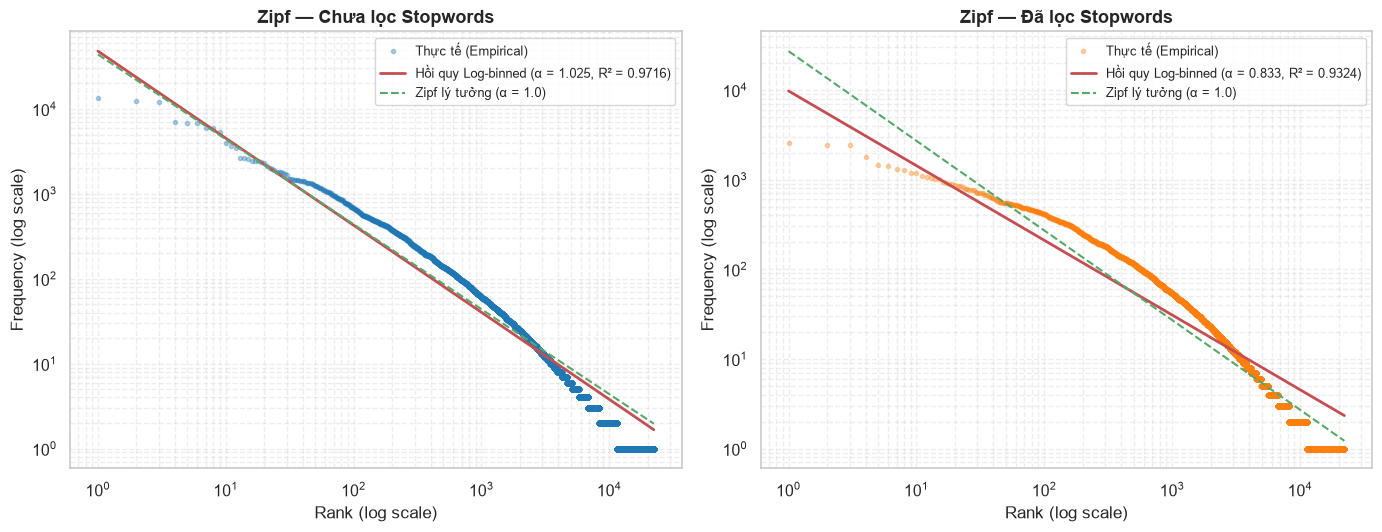

In [102]:
# So sánh phân phối Zipf: Chưa lọc Stopwords vs Đã lọc Stopwords
tokens_with_sw = clean_and_tokenize_eda(df["tweet"], remove_stopwords=False, remove_cashtags=True)
tokens_no_sw = all_tokens  # đã lọc stopwords ở phần TTR

versions = [
    ("Chưa lọc Stopwords", tokens_with_sw, "#1f77b4"),
    ("Đã lọc Stopwords", tokens_no_sw, "#ff7f0e"),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, (title, tokens, color) in zip(axes, versions):
    freqs = np.array([c for _, c in Counter(tokens).most_common()], dtype=float)
    ranks = np.arange(1, len(freqs) + 1, dtype=float)
    log_r, log_f = np.log10(ranks), np.log10(freqs)

    # Log-binned OLS (tránh vùng đuôi freq=1 áp đảo hồi quy)
    edges = np.logspace(0, np.log10(len(freqs)), 41)
    edges[-1] = len(freqs) + 1.0
    bin_r, bin_f = [], []
    for i in range(40):
        m = (ranks >= edges[i]) & (ranks < edges[i + 1])
        if np.any(m):
            bin_r.append(np.mean(log_r[m]))
            bin_f.append(np.mean(log_f[m]))

    slope, intercept, r_val, _, _ = linregress(bin_r, bin_f)
    alpha, r2 = -slope, r_val ** 2
    fitted = 10 ** (intercept + slope * log_r)
    ideal = (freqs.sum() / np.sum(1.0 / ranks)) / ranks

    ax.loglog(ranks, freqs, ".", color=color, alpha=0.35, label="Thực tế (Empirical)")
    ax.loglog(ranks, fitted, "r-", lw=2, label=f"Hồi quy Log-binned (α = {alpha:.3f}, R² = {r2:.4f})")
    ax.loglog(ranks, ideal, "g--", lw=1.5, label="Zipf lý tưởng (α = 1.0)")

    ax.set_title(f"Zipf — {title}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Rank (log scale)")
    ax.set_ylabel("Frequency (log scale)")
    ax.legend(fontsize=9)
    ax.grid(True, which="both", linestyle="--", alpha=0.35)

    hapax_cnt = int((freqs == 1).sum())
    print(f"=== {title} (N = {int(freqs.sum()):,}, V = {len(freqs):,}) ===")
    print(f"Estimated alpha (log-binned): {alpha:.4f} | R²: {r2:.4f}")
    print(f"Hapax legomena (freq = 1)   : {hapax_cnt:,} / {len(freqs):,} ({hapax_cnt / len(freqs) * 100:.2f}%)\n")

plt.tight_layout()
plt.show()

## Đánh giá
- Cả hai phiên bản đều thể hiện rõ tính chất **đuôi dài (long-tail)** đặc trưng của ngôn ngữ tự nhiên, với tỷ lệ từ xuất hiện đúng 1 lần (*hapax legomena*) xấp xỉ **~50%** (tập đã lọc stopwords đạt **48.80%**).

- **Chưa lọc stopwords:** Các từ chức năng tần suất cao (`the`, `to`, `in`, `for`...) tạo phần đầu (head) rõ nét nên đường phân phối bám sát đường Zipf lý tưởng ($\alpha = 1.0$) hơn.

- **Đã lọc stopwords:** Việc loại bỏ stopwords và domain stopwords làm phần đầu bị bẹt xuống rõ rệt, khiến đường thực tế cong hơn và lệch khỏi đường Zipf lý tưởng ở các thứ hạng đầu.

- **Ý nghĩa cho tiền xử lý:** Gần một nửa từ vựng chỉ xuất hiện đúng 1 lần (chủ yếu là typo, tên riêng hiếm hoặc nhiễu từ dữ liệu gốc); ở bước vector hóa (TF-IDF/BoW) nên dùng ngưỡng `min_df` (ví dụ `2–5`) để loại nhiễu và giảm chiều dữ liệu.